# Experiment 5: Binary Classification using Naïve Bayes and K-Nearest Neighbors
**Course:** UCS3512 – Machine Learning Laboratory  
**Department:** Computer Science and Engineering, SSN College of Engineering  
**Student Name:** Thushar TL  
**Register Number:** 312245001188  
**Semester:** V  
**Academic Year:** 2026–2027 (Odd) | **Batch:** 2024–2028  


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import time
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay)

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the Dataset

The Spambase dataset has 4601 emails, 57 numeric features (word/character frequencies and
capital-run-length statistics) and a binary target column `is_spam` (1 = spam, 0 = not spam).

We load it directly from the UCI Machine Learning Repository. If you are working offline,
download `spambase.data` and `spambase.names` from
https://archive.ics.uci.edu/dataset/94/spambase or from the Kaggle page
(https://www.kaggle.com/datasets/colormap/spambase) and place `spambase.data` in the same
folder as this notebook, then just run the `pd.read_csv("spambase.data", header=None)` line
in the `except` block below.

In [2]:
column_names = [
    "word_freq_make","word_freq_address","word_freq_all","word_freq_3d","word_freq_our",
    "word_freq_over","word_freq_remove","word_freq_internet","word_freq_order","word_freq_mail",
    "word_freq_receive","word_freq_will","word_freq_people","word_freq_report","word_freq_addresses",
    "word_freq_free","word_freq_business","word_freq_email","word_freq_you","word_freq_credit",
    "word_freq_your","word_freq_font","word_freq_000","word_freq_money","word_freq_hp",
    "word_freq_hpl","word_freq_george","word_freq_650","word_freq_lab","word_freq_labs",
    "word_freq_telnet","word_freq_857","word_freq_data","word_freq_415","word_freq_85",
    "word_freq_technology","word_freq_1999","word_freq_parts","word_freq_pm","word_freq_direct",
    "word_freq_cs","word_freq_meeting","word_freq_original","word_freq_project","word_freq_re",
    "word_freq_edu","word_freq_table","word_freq_conference","char_freq_semicolon","char_freq_paren",
    "char_freq_bracket","char_freq_bang","char_freq_dollar","char_freq_pound",
    "capital_run_length_average","capital_run_length_longest","capital_run_length_total",
    "is_spam"
]

data_file = "/home/billy/Data/Projects/MLASS/Exercise 5/dataset/spambase.data"
df = pd.read_csv(data_file, header=None, names=column_names)

print(f"Spambase Dataset Loaded from local repository: {data_file}")
print("Shape:", df.shape)
df.head()


Spambase Dataset Loaded from local repository: /home/billy/Data/Projects/MLASS/Exercise 5/dataset/spambase.data
Shape: (4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_paren,char_freq_bracket,char_freq_bang,char_freq_dollar,char_freq_pound,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## 3. Data Preprocessing

In [3]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum().sum(), "total missing values")

# Spambase has no missing values, but we handle it generically in case a local copy differs
df = df.fillna(df.median(numeric_only=True))

# Separate features and target
X = df.drop(columns=["is_spam"])
y = df["is_spam"]

print("Feature matrix shape:", X.shape)
print("Target distribution:\n", y.value_counts())

Missing values per column:
0 total missing values
Feature matrix shape: (4601, 57)
Target distribution:
 is_spam
0    2788
1    1813
Name: count, dtype: int64


In [4]:
# Feature scaling - required for distance-based KNN, optional (but harmless) for Naive Bayes
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X_scaled.describe().T.head()

,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,1.853187e-17,1.000109,-0.342434,-0.342434,-0.342434,-0.342434,14.526998
word_freq_address,4601.0,2.779780e-17,1.000109,-0.165072,-0.165072,-0.165072,-0.165072,10.900965
word_freq_all,4601.0,2.470916e-17,1.000109,-0.556761,-0.556761,-0.556761,0.276427,9.560519
word_freq_3d,4601.0,0.000000e+00,1.000109,-0.046900,-0.046900,-0.046900,-0.046900,30.641278
word_freq_our,4601.0,4.941832e-17,1.000109,-0.464314,-0.464314,-0.464314,0.100792,14.406908


## 4. Exploratory Data Analysis (EDA)

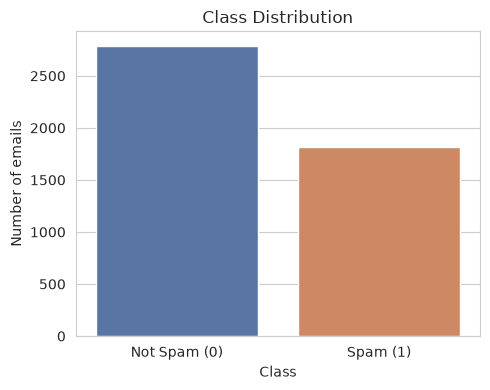

is_spam
0    0.605955
1    0.394045
Name: proportion, dtype: float64


In [5]:
# Class distribution plot
plt.figure(figsize=(5, 4))
sns.countplot(x=y, palette=["#4C72B0", "#DD8452"])
plt.xticks([0, 1], ["Not Spam (0)", "Spam (1)"])
plt.title("Class Distribution")
plt.ylabel("Number of emails")
plt.xlabel("Class")
plt.tight_layout()
plt.show()

print(y.value_counts(normalize=True).rename("proportion"))

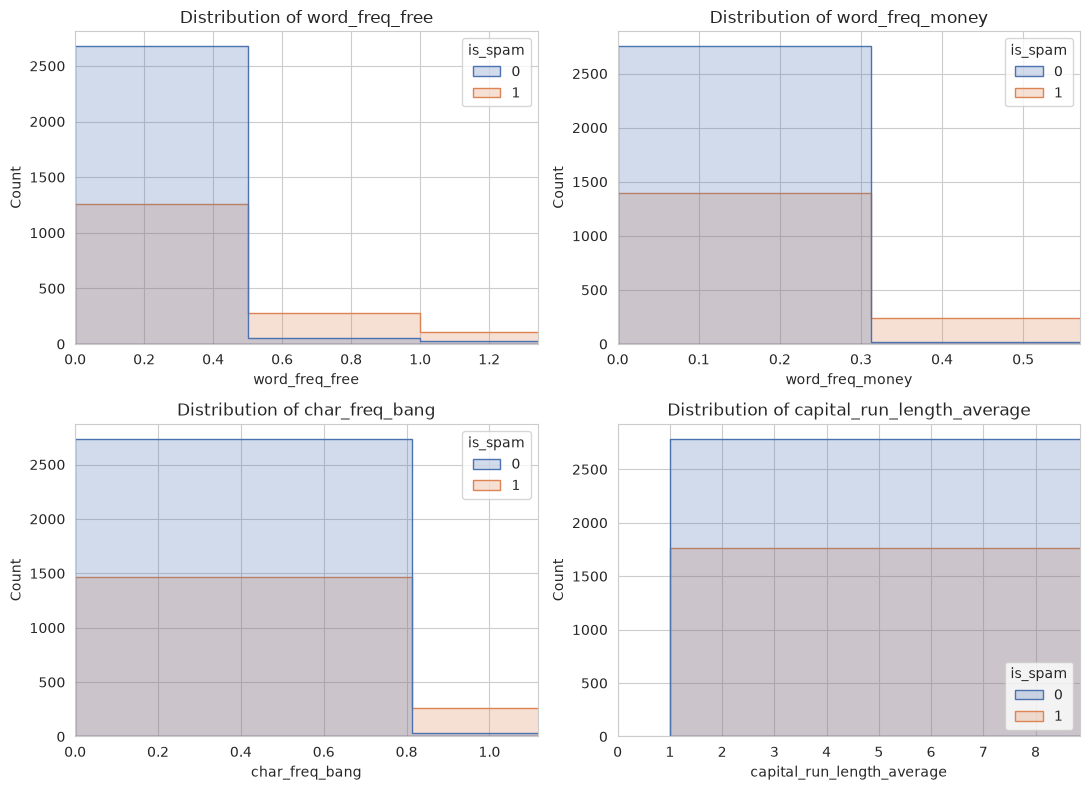

In [6]:
# Feature distribution plots for a few representative features
features_to_plot = ["word_freq_free", "word_freq_money", "char_freq_bang", "capital_run_length_average"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), features_to_plot):
    sns.histplot(data=df, x=col, hue="is_spam", bins=40, kde=False, ax=ax,
                 palette=["#4C72B0", "#DD8452"], element="step")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlim(0, df[col].quantile(0.95))
plt.tight_layout()
plt.show()

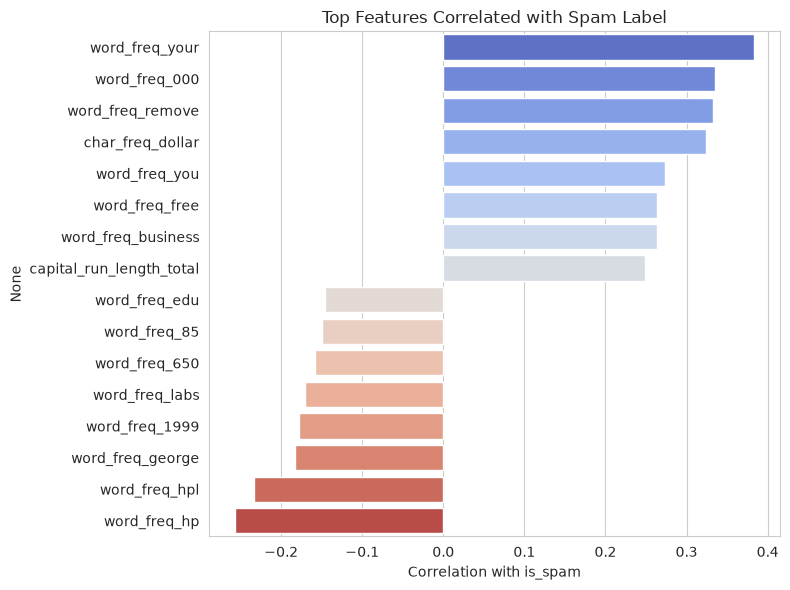

In [7]:
# Correlation heatmap of a subset of features with the target
corr_with_target = df.corr(numeric_only=True)["is_spam"].drop("is_spam").sort_values(ascending=False)
top_corr_features = pd.concat([corr_with_target.head(8), corr_with_target.tail(8)])

plt.figure(figsize=(8, 6))
sns.barplot(x=top_corr_features.values, y=top_corr_features.index, palette="coolwarm")
plt.title("Top Features Correlated with Spam Label")
plt.xlabel("Correlation with is_spam")
plt.tight_layout()
plt.show()

## 5. Train-Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train_scaled, X_test_scaled, _, _ = train_test_split(
    X_scaled, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (3680, 57)  Test shape: (921, 57)


## 6. Naive Bayes Variants

We train three Naive Bayes variants:
- **GaussianNB** - assumes each feature is normally distributed; trained on the scaled features.
- **MultinomialNB** - suited to count/frequency data; trained on the raw (unscaled) non-negative
  word/character frequency features.
- **BernoulliNB** - treats features as binary (present/absent); trained on the raw features
  (sklearn binarizes internally using the `binarize` threshold).

In [9]:
def evaluate_classifier(name, model, X_tr, y_tr, X_te, y_te):
    start_train = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start_train

    start_pred = time.time()
    y_pred = model.predict(X_te)
    pred_time = time.time() - start_pred

    y_prob = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else None

    cm = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)
    fpr_value = fp / (fp + tn)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1 Score": f1_score(y_te, y_pred),
        "Specificity": specificity,
        "FPR": fpr_value,
        "Training Time (s)": train_time,
        "Prediction Time (s)": pred_time,
    }
    return metrics, cm, y_prob

nb_results = []
nb_confusions = {}
nb_probs = {}

gnb = GaussianNB()
m, cm, prob = evaluate_classifier("Gaussian NB", gnb, X_train_scaled, y_train, X_test_scaled, y_test)
nb_results.append(m); nb_confusions["Gaussian NB"] = cm; nb_probs["Gaussian NB"] = prob

mnb = MultinomialNB()
m, cm, prob = evaluate_classifier("Multinomial NB", mnb, X_train, y_train, X_test, y_test)
nb_results.append(m); nb_confusions["Multinomial NB"] = cm; nb_probs["Multinomial NB"] = prob

bnb = BernoulliNB()
m, cm, prob = evaluate_classifier("Bernoulli NB", bnb, X_train, y_train, X_test, y_test)
nb_results.append(m); nb_confusions["Bernoulli NB"] = cm; nb_probs["Bernoulli NB"] = prob

nb_results_df = pd.DataFrame(nb_results).set_index("Model")
nb_results_df

,Accuracy,Precision,Recall,F1 Score,Specificity,FPR,Training Time (s),Prediction Time (s)
Model,,,,,,,,
Gaussian NB,0.832790,0.714579,0.958678,0.818824,0.750896,0.249104,0.003369,0.001105
Multinomial NB,0.776330,0.719888,0.707989,0.713889,0.820789,0.179211,0.002305,0.000767
Bernoulli NB,0.876221,0.871642,0.804408,0.836676,0.922939,0.077061,0.004442,0.001801


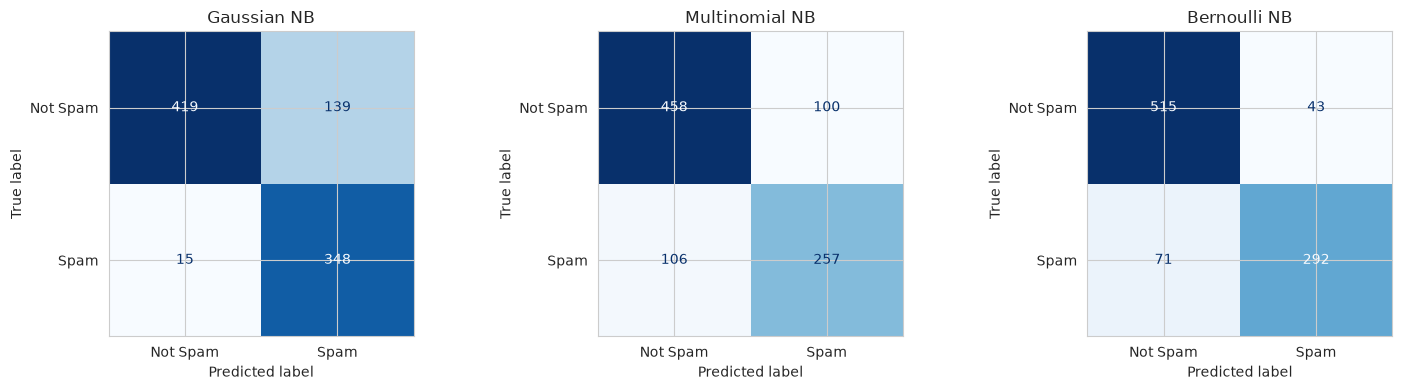

In [10]:
# Confusion matrices for each Naive Bayes variant
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, cm) in zip(axes, nb_confusions.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Spam", "Spam"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

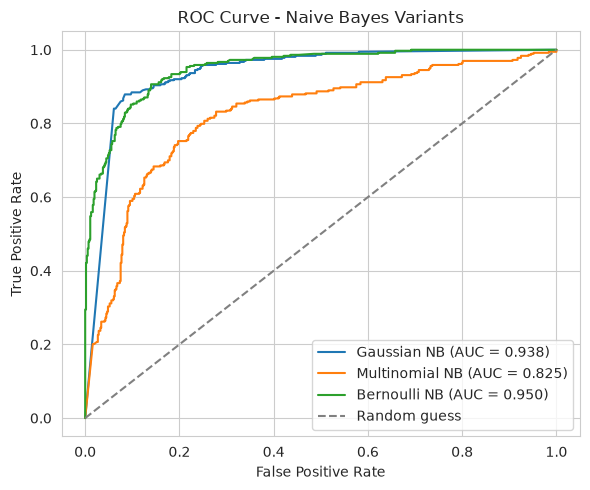

In [11]:
# ROC curves for each Naive Bayes variant
plt.figure(figsize=(6, 5))
for name, prob in nb_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes Variants")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Baseline KNN Classifier

In [12]:
baseline_knn = KNeighborsClassifier(n_neighbors=5)
baseline_metrics, baseline_cm, baseline_prob = evaluate_classifier(
    "KNN (k=5, baseline)", baseline_knn, X_train_scaled, y_train, X_test_scaled, y_test
)
pd.DataFrame([baseline_metrics]).set_index("Model")

,Accuracy,Precision,Recall,F1 Score,Specificity,FPR,Training Time (s),Prediction Time (s)
Model,,,,,,,,
"KNN (k=5, baseline)",0.905537,0.88764,0.870523,0.878999,0.928315,0.071685,0.001696,0.030866


## 8. Hyperparameter Tuning for KNN (5-Fold Cross-Validation)

We tune `n_neighbors`, `weights`, and `metric` using both `GridSearchCV` and
`RandomizedSearchCV` with 5-fold cross-validation on the scaled training data.

In [13]:
param_grid = {
    "n_neighbors": list(range(1, 31)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"],
}

grid_search = GridSearchCV(
    KNeighborsClassifier(), param_grid, cv=5, scoring="accuracy", n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

print("Grid Search best params:", grid_search.best_params_)
print("Grid Search best CV accuracy: {:.4f}".format(grid_search.best_score_))

Grid Search best params: {'metric': 'manhattan', 'n_neighbors': 10, 'weights': 'distance'}
Grid Search best CV accuracy: 0.9247


In [14]:
random_search = RandomizedSearchCV(
    KNeighborsClassifier(), param_grid, n_iter=20, cv=5, scoring="accuracy",
    random_state=RANDOM_STATE, n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)

print("Randomized Search best params:", random_search.best_params_)
print("Randomized Search best CV accuracy: {:.4f}".format(random_search.best_score_))

Randomized Search best params: {'weights': 'distance', 'n_neighbors': 7, 'metric': 'manhattan'}
Randomized Search best CV accuracy: 0.9187


In [15]:
tuning_results_df = pd.DataFrame({
    "Search Method": ["Grid Search", "Randomized Search"],
    "Best k": [grid_search.best_params_["n_neighbors"], random_search.best_params_["n_neighbors"]],
    "Best CV Accuracy": [grid_search.best_score_, random_search.best_score_],
    "Best Parameters": [grid_search.best_params_, random_search.best_params_],
})
tuning_results_df

,Search Method,Best k,Best CV Accuracy,Best Parameters
0,Grid Search,10,0.924728,"{'metric': 'manhattan', 'n_neighbors': 10, 'we..."
1,Randomized Search,7,0.918750,"{'weights': 'distance', 'n_neighbors': 7, 'met..."


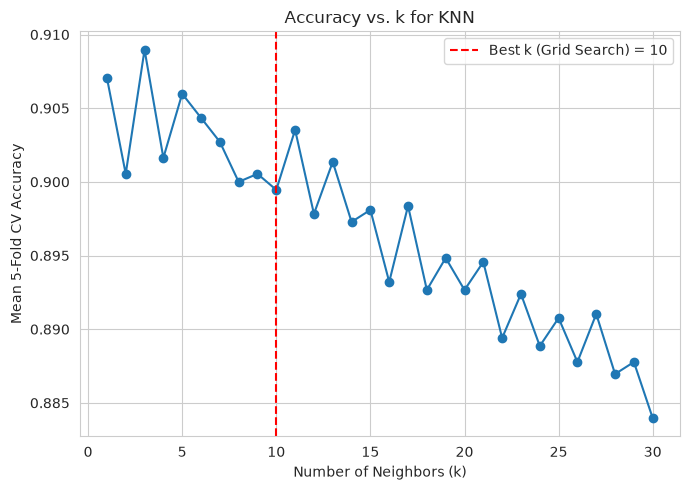

In [16]:
# Accuracy vs k plot
k_range = list(range(1, 31))
cv_scores = []
for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_k, X_train_scaled, y_train, cv=5, scoring="accuracy")
    cv_scores.append(scores.mean())

plt.figure(figsize=(7, 5))
plt.plot(k_range, cv_scores, marker="o")
plt.axvline(grid_search.best_params_["n_neighbors"], color="red", linestyle="--",
            label=f"Best k (Grid Search) = {grid_search.best_params_['n_neighbors']}")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean 5-Fold CV Accuracy")
plt.title("Accuracy vs. k for KNN")
plt.legend()
plt.tight_layout()
plt.show()

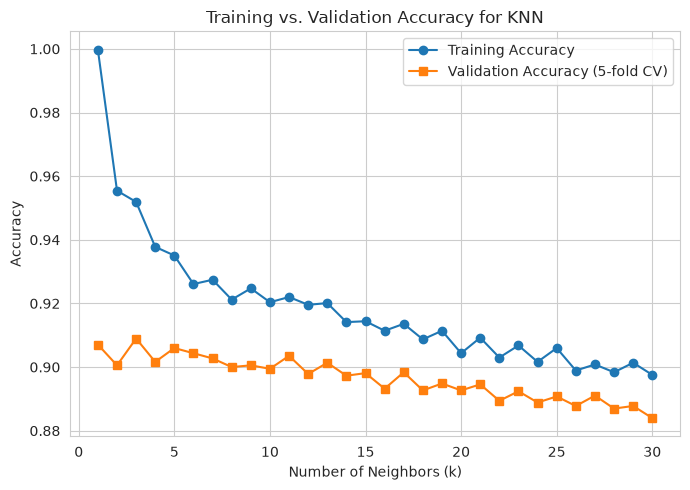

In [17]:
# Training vs validation accuracy plot (to visualize overfitting/underfitting)
train_acc, val_acc = [], []
for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_train_scaled, y_train)
    train_acc.append(accuracy_score(y_train, knn_k.predict(X_train_scaled)))
    val_scores = cross_val_score(knn_k, X_train_scaled, y_train, cv=5, scoring="accuracy")
    val_acc.append(val_scores.mean())

plt.figure(figsize=(7, 5))
plt.plot(k_range, train_acc, marker="o", label="Training Accuracy")
plt.plot(k_range, val_acc, marker="s", label="Validation Accuracy (5-fold CV)")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("Training vs. Validation Accuracy for KNN")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Optimized KNN using KDTree and BallTree

Using the best `k` and parameters found by Grid Search, we train two KNN models that differ
only in the neighbor-search algorithm (`kd_tree` vs `ball_tree`) and compare their
performance and computational cost.

In [18]:
best_params = grid_search.best_params_
best_k = best_params["n_neighbors"]

knn_kdtree = KNeighborsClassifier(
    n_neighbors=best_k, weights=best_params["weights"], metric=best_params["metric"],
    algorithm="kd_tree"
)
kdtree_metrics, kdtree_cm, kdtree_prob = evaluate_classifier(
    "KNN (KDTree)", knn_kdtree, X_train_scaled, y_train, X_test_scaled, y_test
)

knn_balltree = KNeighborsClassifier(
    n_neighbors=best_k, weights=best_params["weights"], metric=best_params["metric"],
    algorithm="ball_tree"
)
balltree_metrics, balltree_cm, balltree_prob = evaluate_classifier(
    "KNN (BallTree)", knn_balltree, X_train_scaled, y_train, X_test_scaled, y_test
)

search_comparison_df = pd.DataFrame([kdtree_metrics, balltree_metrics]).set_index("Model")
search_comparison_df

,Accuracy,Precision,Recall,F1 Score,Specificity,FPR,Training Time (s),Prediction Time (s)
Model,,,,,,,,
KNN (KDTree),0.918567,0.939024,0.848485,0.891462,0.964158,0.035842,0.016266,0.122655
KNN (BallTree),0.918567,0.939024,0.848485,0.891462,0.964158,0.035842,0.021394,0.095968


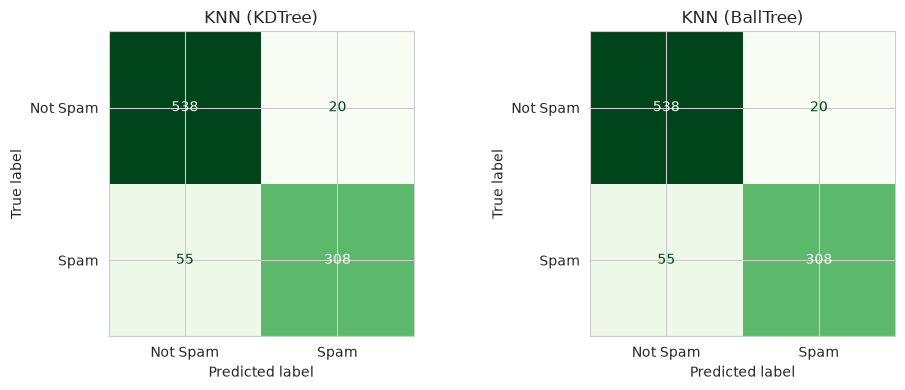

In [19]:
# Confusion matrices - KDTree vs BallTree
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, cm) in zip(axes, [("KNN (KDTree)", kdtree_cm), ("KNN (BallTree)", balltree_cm)]):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Spam", "Spam"])
    disp.plot(ax=ax, colorbar=False, cmap="Greens")
    ax.set_title(name)
plt.tight_layout()
plt.show()

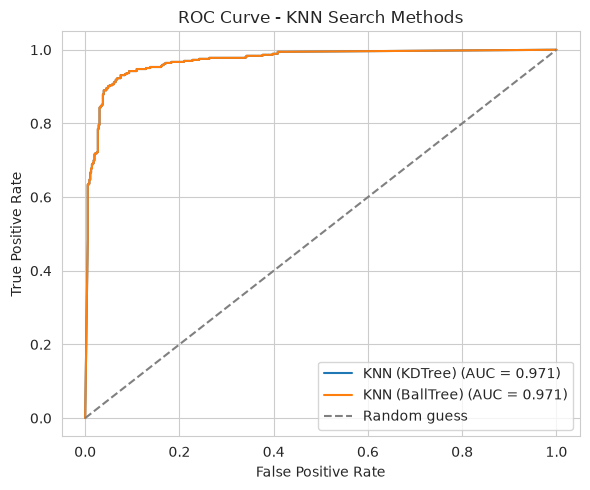

In [20]:
# ROC curves - KDTree vs BallTree
plt.figure(figsize=(6, 5))
for name, prob in [("KNN (KDTree)", kdtree_prob), ("KNN (BallTree)", balltree_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN Search Methods")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Consolidated Performance Comparison

In [21]:
all_results_df = pd.concat([
    nb_results_df,
    pd.DataFrame([baseline_metrics]).set_index("Model"),
    search_comparison_df
])
all_results_df.round(4)

,Accuracy,Precision,Recall,F1 Score,Specificity,FPR,Training Time (s),Prediction Time (s)
Model,,,,,,,,
Gaussian NB,0.8328,0.7146,0.9587,0.8188,0.7509,0.2491,0.0034,0.0011
Multinomial NB,0.7763,0.7199,0.7080,0.7139,0.8208,0.1792,0.0023,0.0008
Bernoulli NB,0.8762,0.8716,0.8044,0.8367,0.9229,0.0771,0.0044,0.0018
"KNN (k=5, baseline)",0.9055,0.8876,0.8705,0.8790,0.9283,0.0717,0.0017,0.0309
KNN (KDTree),0.9186,0.9390,0.8485,0.8915,0.9642,0.0358,0.0163,0.1227
KNN (BallTree),0.9186,0.9390,0.8485,0.8915,0.9642,0.0358,0.0214,0.0960


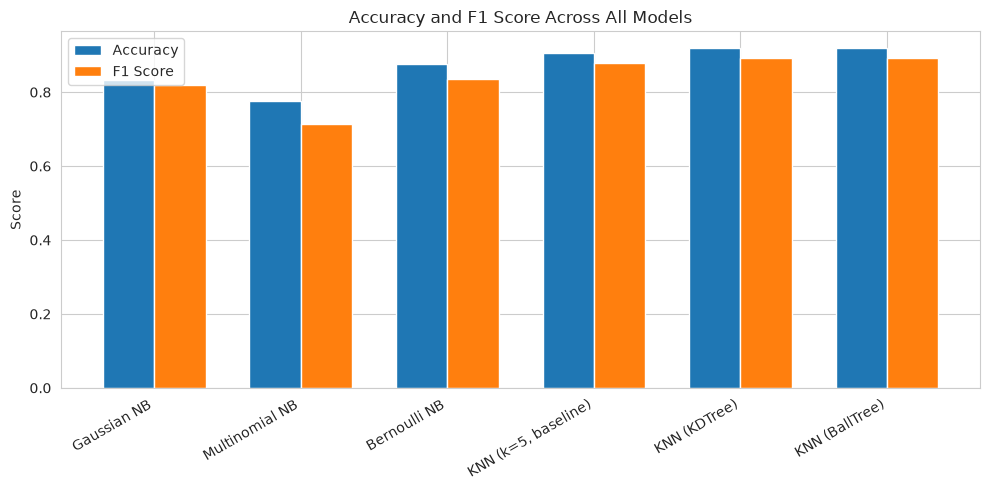

In [22]:
# Bar chart comparing accuracy and F1 score across all models
plt.figure(figsize=(10, 5))
x = np.arange(len(all_results_df))
width = 0.35
plt.bar(x - width/2, all_results_df["Accuracy"], width, label="Accuracy")
plt.bar(x + width/2, all_results_df["F1 Score"], width, label="F1 Score")
plt.xticks(x, all_results_df.index, rotation=30, ha="right")
plt.ylabel("Score")
plt.title("Accuracy and F1 Score Across All Models")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Overfitting and Underfitting Analysis

Use the "Training vs. Validation Accuracy" plot from Section 8 to answer the following in
your report:

- **Difference between training and validation accuracy:** A large gap (training accuracy
  much higher than validation accuracy) indicates overfitting; both curves being low and
  close together indicates underfitting.
- **Effect of small k:** Small k (e.g., k = 1) makes KNN sensitive to noise in the training
  data - it memorizes individual points, giving high training accuracy but lower, more
  volatile validation accuracy (high variance / overfitting).
- **Effect of large k:** Large k over-smooths the decision boundary, pulling in points from
  the majority class and reducing both training and validation accuracy (higher bias /
  underfitting).
- **Role of hyperparameter tuning:** Cross-validated search (Grid/Randomized Search) selects
  the k (and distance metric/weighting) that balances this trade-off, improving
  generalization to unseen data rather than just fitting the training set.

Fill in the specific numeric gap you observe from your run of Section 8's plot when writing
the report.

## 12. Bias-Variance Analysis

- **Bias behavior of Naive Bayes:** Naive Bayes makes a strong assumption (conditional
  independence of features given the class), which introduces relatively high bias. Because
  the model is simple, it tends to have low variance - performance is fairly stable across
  different training samples, but accuracy is capped by how well the independence
  assumption fits the true data distribution.
- **Variance behavior of KNN:** KNN has low bias (it makes almost no assumption about the
  data's structure) but high variance, especially for small k - predictions can change a lot
  with small changes in the training data or a new query point's exact neighbors.
- **Effect of tuning on the bias-variance trade-off:** Increasing k in KNN increases bias and
  decreases variance (smoother decision boundary); decreasing k does the opposite.
  Hyperparameter tuning via cross-validation searches this bias-variance spectrum for the k
  (and metric/weights) that minimizes validation error, i.e., the best trade-off point for
  this dataset.

Update this section with the specific trend you observe (e.g., "validation accuracy peaked
around k = <value>, after which increasing k reduced accuracy, indicating growing bias").

## 13. Conclusion

- Summarize which Naive Bayes variant performed best on Spambase and why (Bernoulli/Multinomial
  NB typically outperform Gaussian NB on this dataset since features are frequency/count-like
  rather than normally distributed).
- Report the optimal k and hyperparameters found by Grid Search and Randomized Search, and
  note whether they agreed.
- Compare KDTree and BallTree in terms of accuracy (should be identical/near-identical, since
  both give exact nearest-neighbor results) and computational cost (training/prediction time),
  and comment on which is preferable for this dataset size and dimensionality.
- Comment on overall generalization: which model (Naive Bayes vs. tuned KNN) generalizes
  better to the test set, and why, referencing the bias-variance discussion above.

(Write your final numeric observations here after running all cells above.)